# `Library`

In [1]:
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
Target = "Outcome"

# `Data Loading & Understanding`

### Data Load

In [2]:
current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
file_path = os.path.join(parent_dir, "data", "Pima_Indians_diabetes_dataset(PIDD).xlsx")
df = pd.read_excel(file_path)
df.shape

(768, 9)

In [3]:
df.head(10)

,Pregnancies,Glucose,Blood pressure,Skin thickness,Insulin,Body mass index,Diabetes pedigree function,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


### Data Info

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Pregnancies                 768 non-null    int64  
 1   Glucose                     768 non-null    int64  
 2   Blood pressure              768 non-null    int64  
 3   Skin thickness              768 non-null    int64  
 4   Insulin                     768 non-null    int64  
 5   Body mass index             768 non-null    float64
 6   Diabetes pedigree function  768 non-null    float64
 7   Age                         768 non-null    int64  
 8   Outcome                     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
Blood pressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
Skin thickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
Body mass index,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
Diabetes pedigree function,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


### NULL Checking

In [6]:
df.isnull().sum()

Pregnancies                   0
Glucose                       0
Blood pressure                0
Skin thickness                0
Insulin                       0
Body mass index               0
Diabetes pedigree function    0
Age                           0
Outcome                       0
dtype: int64

In [7]:
(df == 0).sum()

Pregnancies                   111
Glucose                         5
Blood pressure                 35
Skin thickness                227
Insulin                       374
Body mass index                11
Diabetes pedigree function      0
Age                             0
Outcome                       500
dtype: int64

### Duplicate Checking

In [8]:
duplicate = df[df.duplicated()]
duplicate.count()

Pregnancies                   0
Glucose                       0
Blood pressure                0
Skin thickness                0
Insulin                       0
Body mass index               0
Diabetes pedigree function    0
Age                           0
Outcome                       0
dtype: int64

### Rename Columns

In [9]:
df = df.rename(columns={
    "Blood pressure": "BloodPressure",
    "Skin thickness": "SkinThickness",
    "Body mass index": "BMI",
    "Diabetes pedigree function": "DiabetesPedigreeFunction",
})
df.columns.tolist()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

### Handle Hidden Missing Values

In [10]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)
df_clean.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

### Counting the Outcome 

In [11]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

# `Exploratory Data Analysis (EDA)`

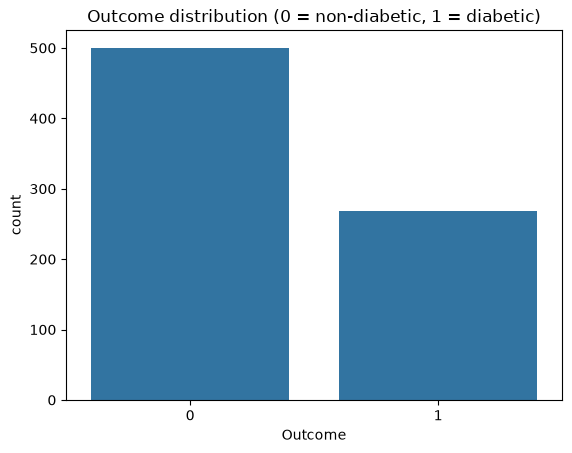

In [12]:
sns.countplot(x="Outcome", data=df)
plt.title("Outcome distribution (0 = non-diabetic, 1 = diabetic)")
plt.show()

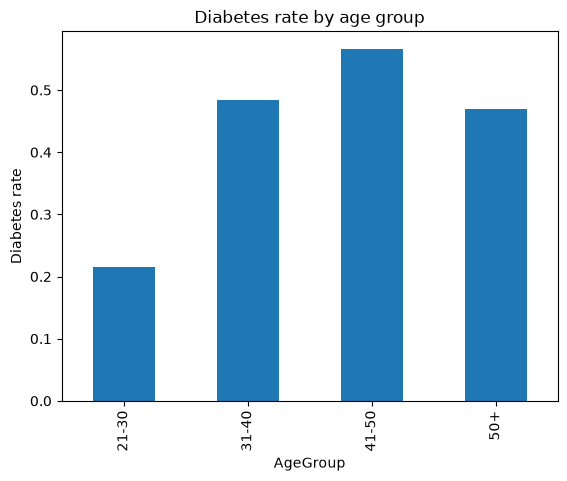

In [17]:
df_clean["AgeGroup"] = pd.cut(df_clean["Age"], bins=[20, 30, 40, 50, 100], labels=["21-30", "31-40", "41-50", "50+"])
df_clean.groupby("AgeGroup")["Outcome"].mean().plot(kind="bar")
plt.ylabel("Diabetes rate")
plt.title("Diabetes rate by age group")
plt.show()
df_clean = df_clean.drop(columns="AgeGroup")

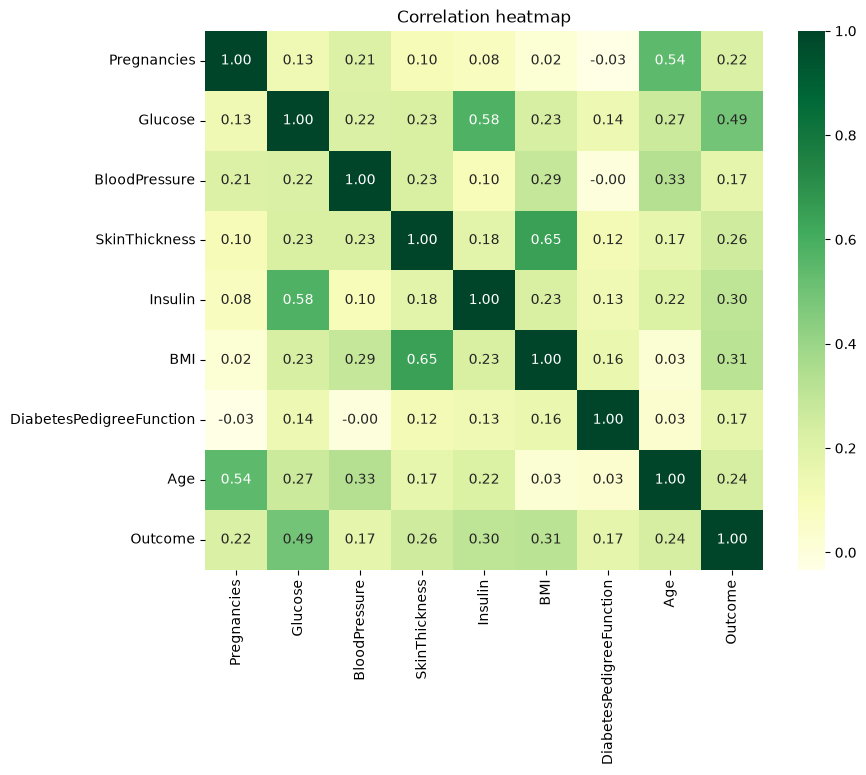

In [19]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="YlGn")
plt.title("Correlation heatmap")
plt.show()